<style>
/* Palatia typography for notebook narrative cells; code cells retain monospace styling. */
.jp-RenderedMarkdown h1, .jp-RenderedMarkdown h2, .jp-RenderedMarkdown h3,
.jp-RenderedMarkdown h4, .jp-RenderedMarkdown h5, .jp-RenderedMarkdown h6,
.jp-RenderedMarkdown p, .jp-RenderedMarkdown li, .jp-RenderedMarkdown blockquote,
.jp-RenderedMarkdown table, .jp-RenderedMarkdown th, .jp-RenderedMarkdown td,
.markdown h1, .markdown h2, .markdown h3, .markdown h4, .markdown h5, .markdown h6,
.markdown p, .markdown li, .markdown blockquote, .markdown table,
.colab-rendered-markdown h1, .colab-rendered-markdown h2, .colab-rendered-markdown h3,
.colab-rendered-markdown h4, .colab-rendered-markdown h5, .colab-rendered-markdown h6,
.colab-rendered-markdown p, .colab-rendered-markdown li,
.colab-rendered-markdown blockquote, .colab-rendered-markdown table {
  font-family: Palatia, 'Palatino Linotype', 'Book Antiqua', serif !important;
}
</style>

# Methane Pyrolysis: FNN, BNN, and H-BNN Modelling

This notebook implements the supplied methane-pyrolysis modelling workflow. It includes data preparation, preliminary dataset analysis, shared hyperparameter search, FNN/BNN/H-BNN training and evaluation, post-processing, and model-comparison plots.

Run the notebook from top to bottom in order. The modelling and plotting cells depend on variables created by earlier cells.

<div style="font-family: Palatia, 'Palatino Linotype', 'Book Antiqua', serif;">
<h2>1. Data preparation, feature engineering, splitting, scaling, and augmentation</h2>
Loads `MP___DATA___SHEET.csv`, constructs the interval hydrogen production rate target, encodes the operating variables, creates train/validation/test sets, scales the continuous inputs and target, and augments only the training data.
</div>

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# 1. Load and clean

raw_df = pd.read_csv('/content/MP___DATA___SHEET.csv')
raw_df.columns = [c.strip() for c in raw_df.columns]

# For reproducibility, rename only what is needed so the framework remains unchanged
raw_df = raw_df.rename(columns={
    'P(W)': 'p(W)',
    'MoH_interval (kg)': 'MoH_interval(kg)',
    'E_cum(kWh)': 'Energy_cum(kWh)' # Corrected column name
})

# Keep only rows needed here
required_cols = [
    'F(mL/h)', 'T(C)', 'p(W)', 'TOS(h)', 'Delta_t(h)',
    'n_CH4_in(mol/h)', 'Energy_cum(kWh)', 'MoH_interval(kg)'
]
raw_df = raw_df.dropna(subset=required_cols).copy()

# Remove zero/negative interval rows before interval-rate calculation
raw_df = raw_df[raw_df['Delta_t(h)'] > 0].copy()


# 2. Feature engineering

raw_df['TOS_mid(h)'] = raw_df['TOS(h)'] - 0.5 * raw_df['Delta_t(h)']

# Primary target: interval H2 production rate [g/h]
raw_df['rH2_interval(g/h)'] = 1000.0 * raw_df['MoH_interval(kg)'] / raw_df['Delta_t(h)']

# Positive target transform
eps = 1e-12
raw_df['log_rH2'] = np.log(np.clip(raw_df['rH2_interval(g/h)'], eps, None))


# 3. Aggregate exact duplicate operating points. Keeps mean target and replicate spread
group_cols = ['F(mL/h)', 'T(C)', 'p(W)', 'TOS(h)', 'Delta_t(h)', 'TOS_mid(h)']

agg_df = (
    raw_df.groupby(group_cols, as_index=False)
    .agg({
        'log_rH2': ['mean', 'std', 'count'],
        'MoH_interval(kg)': 'mean',
        'n_CH4_in(mol/h)': 'mean',
        'Energy_cum(kWh)': 'mean',
        'VoH_cum(mL)': 'mean'
    })
)

agg_df.columns = [
    'F(mL/h)', 'T(C)', 'p(W)', 'TOS(h)', 'Delta_t(h)', 'TOS_mid(h)',
    'log_rH2_mean', 'log_rH2_std', 'rep_count',
    'MoH_interval_mean(kg)', 'n_CH4_in_mean(mol/h)',
    'Energy_cum_mean(kWh)', 'VoH_cum_mean(mL)'
]

agg_df['log_rH2_std'] = agg_df['log_rH2_std'].fillna(0.0)


# 4. Encode features
#    Continuous: T(C), TOS_mid(h)
#    Categorical: F, p, Delta_t

continuous_cols = ['T(C)', 'TOS_mid(h)']
categorical_cols = ['F(mL/h)', 'p(W)', 'Delta_t(h)']

X_cont = agg_df[continuous_cols].copy()
X_cat = pd.get_dummies(agg_df[categorical_cols].astype(str), drop_first=False)

X_all = pd.concat([X_cont, X_cat], axis=1)
y_all = agg_df[['log_rH2_mean']].copy()


# 5. Split
X_train_raw, X_temp_raw, y_train_raw, y_temp_raw, train_meta, temp_meta = train_test_split(
    X_all, y_all, agg_df, test_size=0.30, random_state=42
)

X_val_raw, X_test_raw, y_val_raw, y_test_raw, val_meta, test_meta = train_test_split(
    X_temp_raw, y_temp_raw, temp_meta, test_size=0.50, random_state=42
)


# 6. Scale using training only
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = X_train_raw.copy()
X_val_scaled = X_val_raw.copy()
X_test_scaled = X_test_raw.copy()

X_train_scaled[continuous_cols] = x_scaler.fit_transform(X_train_raw[continuous_cols])
X_val_scaled[continuous_cols]   = x_scaler.transform(X_val_raw[continuous_cols])
X_test_scaled[continuous_cols]  = x_scaler.transform(X_test_raw[continuous_cols])

y_train_scaled = y_scaler.fit_transform(y_train_raw)
y_val_scaled   = y_scaler.transform(y_val_raw)
y_test_scaled  = y_scaler.transform(y_test_raw)

# Convert to numpy
X_train_scaled = X_train_scaled.values.astype(float)
X_val_scaled   = X_val_scaled.values.astype(float)
X_test_scaled  = X_test_scaled.values.astype(float)

y_train_scaled = y_train_scaled.astype(float)
y_val_scaled   = y_val_scaled.astype(float)
y_test_scaled  = y_test_scaled.astype(float)

# 7. Training-only bootstrap augmentation
#    with Gaussian noise on continuous features
#    scale = 2, 5, or 10

# Number of continuous feature columns (must match continuous_cols order in X_train_scaled)
N_CONT_COLS = len(continuous_cols)  # Here ---> T(C) and TOS_mid(h) — columns 0 and 1

def augment_training_set(X_train, y_train, scale=5, noise_std=0.15, random_state=42):

    rng = np.random.default_rng(random_state)
    n = len(X_train)

    if scale <= 1:
        return X_train.copy(), y_train.copy()

    n_final = int(scale * n)

    # Bootstrap resampling
    idx = rng.integers(0, n, size=n_final)
    X_aug = X_train[idx].copy()
    y_aug = y_train[idx].copy()

    # Gaussian noise on continuous features only
    noise_X = rng.normal(loc=0.0, scale=noise_std, size=(n_final, N_CONT_COLS))
    X_aug[:, :N_CONT_COLS] += noise_X

    # Small Gaussian noise on target (log-space)
    noise_y = rng.normal(loc=0.0, scale=noise_std, size=y_aug.shape)
    y_aug += noise_y

    return X_aug, y_aug

# choose augmentation scale here
AUG_SCALE = 10  # try 2, 5, 10

X_train_aug, y_train_aug = augment_training_set(
    X_train_scaled, y_train_scaled, scale=AUG_SCALE, noise_std=0.15, random_state=42
)

print("Train:", X_train_aug.shape, y_train_aug.shape)
print("Val  :", X_val_scaled.shape, y_val_scaled.shape)
print("Test :", X_test_scaled.shape, y_test_scaled.shape)

Train: (1130, 47) (1130, 1)
Val  : (24, 47) (24, 1)
Test : (25, 47) (25, 1)


<div style="font-family: Palatia, 'Palatino Linotype', 'Book Antiqua', serif;">
<h2>2. Preliminary analysis of the methane pyrolysis dataset</h2>
Calculates the descriptive statistics, correlation matrix, temperature grouped SEC statistics, and minimum SEC row from "raw_df".
</div>

In [2]:
### PRELIMINARY DATA ANALYSIS OF THE RAW DATASET (METHANE PYROLYSIS) ###

# Specific Energy Consumption (SEC) - derived from interval energy and H2 mass
# SEC_interval(kWh/kgH2) = Energy_interval(kWh) / (MoH_interval(kg))
raw_df['SEC_interval(kWh/kgH2)'] = raw_df['Energy_interval(kWh)'] / (raw_df['MoH_interval(kg)'] + 1e-12)

# YH2(%) is derived from Y_H2_cum_measured(%) based on kernel state
raw_df = raw_df.rename(columns={'Y_H2_cum_measured(%)': 'YH2(%)'})

# Filtering operational data:
# MoH_interval(kg) > 0 and valid SEC
df_operational = raw_df[
    (raw_df['MoH_interval(kg)'] > 0) &
    (raw_df['SEC_interval(kWh/kgH2)'].notna()) &
    (raw_df['YH2(%)'].notna())
].copy()

# Convert relevant columns to numeric, coercing errors
numeric_cols = [
    'p(W)', 'T(C)', 'F(mL/h)', 'TOS(h)',
    'SEC_interval(kWh/kgH2)', 'YH2(%)', 'MoH_interval(kg)'
]
for col in numeric_cols:
    df_operational[col] = pd.to_numeric(df_operational[col], errors='coerce')

# Drop rows where essential variables became NaN after coercion
df_operational.dropna(
    subset=['SEC_interval(kWh/kgH2)', 'YH2(%)', 'MoH_interval(kg)'],
    inplace=True
)

# 1. Descriptive statistics of key derived variables
print("### 1. Descriptive Statistics of Derived Variables:\n ###")
desc_stats = df_operational[
    ['SEC_interval(kWh/kgH2)', 'YH2(%)', 'MoH_interval(kg)']
].describe()
print(desc_stats)
print("\n")

# 2. Correlation analysis of key input/output variables
correlation_cols = [
    'p(W)', 'T(C)', 'F(mL/h)', 'TOS(h)',
    'SEC_interval(kWh/kgH2)', 'YH2(%)', 'MoH_interval(kg)'
]
correlation_matrix = df_operational.dropna(
    subset=correlation_cols
)[correlation_cols].corr(numeric_only=True)

print("### 2. Correlation Matrix of Key Parameters:\n ###")
print(correlation_matrix)
print("\n")

# 3. Grouped SEC analysis by temperature
# Replaces SMR magnetic-flux analysis because B(mT) is not present in MP dataset
temp_sec_analysis = df_operational.groupby('T(C)')['SEC_interval(kWh/kgH2)'].agg(
    ['mean', 'median', 'min', 'max', 'count']
)

print("### 3. Grouped Analysis of SEC by Temperature (T(C)):\n ###")
print(temp_sec_analysis)
print("\n")


# 4. Identify the most energy-efficient row (lowest SEC)
if not df_operational.empty:
    optimal_row_sec = df_operational.loc[
        df_operational['SEC_interval(kWh/kgH2)'].idxmin()
    ]

    print("### 4. Most Energy-Efficient Operating Point (Lowest SEC):\n ###")
    print("The row representing the most energy-efficient operating point (lowest SEC) is:\n")
    print(
        optimal_row_sec[
            ['p(W)', 'T(C)', 'F(mL/h)', 'TOS(h)',
             'MoH_interval(kg)', 'SEC_interval(kWh/kgH2)', 'YH2(%)']
        ].to_markdown(index=True)
    )
else:
    print("No operational data available (no MoH_interval(kg) > 0 or SEC is NaN). Cannot identify optimal point.")

print("\n")

### 1. Descriptive Statistics of Derived Variables:
 ###
       SEC_interval(kWh/kgH2)      YH2(%)  MoH_interval(kg)
count              162.000000  162.000000        162.000000
mean             14426.334582   32.617284          0.000069
std              21577.016424   17.901086          0.000059
min                833.333322    3.000000          0.000005
25%                967.741923    9.000000          0.000030
50%               2222.782230   41.500000          0.000064
75%              23769.228885   45.000000          0.000079
max             112499.994375   56.000000          0.000450


### 2. Correlation Matrix of Key Parameters:
 ###
                            p(W)      T(C)  F(mL/h)    TOS(h)  \
p(W)                    1.000000 -0.343764      NaN -0.531300   
T(C)                   -0.343764  1.000000      NaN  0.491162   
F(mL/h)                      NaN       NaN      NaN       NaN   
TOS(h)                 -0.531300  0.491162      NaN  1.000000   
SEC_interval(kWh/kgH2)  0.

<div style="font-family: Palatia, 'Palatino Linotype', 'Book Antiqua', serif;">
<h2>3. Shared architecture and hyperparameter search</h2>
Searches the shared FNN backbone and the dropout setting used by the downstream BNN and H-BNN blocks.
</div>

In [3]:
### SHARED ARCHITECTURE / HYPERPARAMETER SEARCH BLOCK FOR FNN, BNN, AND H-BNN ###
### METHANE PYROLYSIS VERSION ###
### PLACE THIS BLOCK AFTER THE AUGMENTATION + SPLITTING + SCALING BLOCK ###

import copy
import time
import itertools
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# DataLoaders
batch_size = 32

train_ds = TensorDataset(
    torch.tensor(X_train_aug, dtype=torch.float32),
    torch.tensor(y_train_aug, dtype=torch.float32)
)
val_ds = TensorDataset(
    torch.tensor(X_val_scaled, dtype=torch.float32),
    torch.tensor(y_val_scaled, dtype=torch.float32)
)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

input_dim = X_train_aug.shape[1]

# Search models
class SearchFNN(nn.Module):
    def __init__(self, input_dim, hidden_dims, activation='ReLU'):
        super(SearchFNN, self).__init__()
        act_fn = {'ReLU': nn.ReLU, 'Tanh': nn.Tanh, 'GELU': nn.GELU}[activation]

        layers = []
        in_dim = input_dim
        for h_dim in hidden_dims:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(act_fn())
            in_dim = h_dim
        layers.append(nn.Linear(in_dim, 1))

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class SearchBNN(nn.Module):
    def __init__(self, input_dim, hidden_dims, activation='ReLU', dropout=0.05):
        super(SearchBNN, self).__init__()
        act_fn = {'ReLU': nn.ReLU, 'Tanh': nn.Tanh, 'GELU': nn.GELU}[activation]

        layers = []
        in_dim = input_dim
        for h_dim in hidden_dims:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(nn.Dropout(dropout))
            layers.append(act_fn())
            in_dim = h_dim
        layers.append(nn.Linear(in_dim, 1))

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

# Optimizer builder
def build_optimizer(model, optimizer_name='Adam', lr=1e-3, weight_decay=1e-5):
    if optimizer_name == 'Adam':
        return optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer_name == 'AdamW':
        return optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer_name == 'RMSprop':
        return optim.RMSprop(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_name}")

# Generic train/eval search function
def train_for_search(model, train_loader, val_loader,
                     n_epochs=250, lr=1e-3, patience=50,
                     weight_decay=1e-5, optimizer_name='Adam'):
    optimizer = build_optimizer(
        model=model,
        optimizer_name=optimizer_name,
        lr=lr,
        weight_decay=weight_decay
    )
    criterion = nn.MSELoss()

    best_model_state = None
    best_val_loss = float('inf')
    wait = 0

    for epoch in range(n_epochs):
        model.train()
        for xb, yb in train_loader:
            optimizer.zero_grad()
            y_pred = model(xb)
            loss = criterion(y_pred, yb)
            loss.backward()
            optimizer.step()

        model.eval()
        epoch_val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                y_pred = model(xb)
                epoch_val_loss += criterion(y_pred, yb).item()

        epoch_val_loss /= len(val_loader)

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    return model, best_val_loss

# Step 1: Shared backbone search using FNN
ARCH_CANDIDATES = [
    [32, 16, 8],
    [64, 32, 16],
    [128, 64, 32],
    [256, 128, 64]
]

ACTIVATION_CANDIDATES = ['ReLU', 'Tanh', 'GELU']
LR_CANDIDATES = [1e-3, 3e-4]
WD_CANDIDATES = [1e-5, 1e-4]
OPTIMIZER_CANDIDATES = ['Adam', 'AdamW', 'RMSprop']

shared_search_results = []
best_shared_config = None
best_shared_val_loss = float('inf')

print("\nSHARED BACKBONE SEARCH (USING FNN) ")

for hidden_dims, activation, lr, wd, optimizer_name in itertools.product(
    ARCH_CANDIDATES,
    ACTIVATION_CANDIDATES,
    LR_CANDIDATES,
    WD_CANDIDATES,
    OPTIMIZER_CANDIDATES
):
    torch.manual_seed(42)
    np.random.seed(42)

    model = SearchFNN(
        input_dim=input_dim,
        hidden_dims=hidden_dims,
        activation=activation
    )

    start_time = time.time()
    model, val_loss = train_for_search(
        model,
        train_loader,
        val_loader,
        n_epochs=250,
        lr=lr,
        patience=50,
        weight_decay=wd,
        optimizer_name=optimizer_name
    )
    run_time = time.time() - start_time

    result = {
        'hidden_dims': hidden_dims,
        'activation': activation,
        'lr': lr,
        'weight_decay': wd,
        'optimizer': optimizer_name,
        'val_loss': val_loss,
        'time_sec': run_time
    }
    shared_search_results.append(result)
    print(result)

    if val_loss < best_shared_val_loss:
        best_shared_val_loss = val_loss
        best_shared_config = result

print("\nBest shared backbone configuration:")
print(best_shared_config)

BEST_HIDDEN_DIMS   = best_shared_config['hidden_dims']
BEST_ACTIVATION    = best_shared_config['activation']
BEST_LR            = best_shared_config['lr']
BEST_WEIGHT_DECAY  = best_shared_config['weight_decay']
BEST_OPTIMIZER     = best_shared_config['optimizer']

# Step 2: Dropout sweep for BNN / H-BNN
# same backbone for fairness
DROPOUT_CANDIDATES = [0.02, 0.05, 0.10]

dropout_search_results = []
best_dropout = None
best_dropout_val_loss = float('inf')

print("\nDROPOUT SEARCH FOR BNN / H-BNN: ")

for dropout in DROPOUT_CANDIDATES:
    torch.manual_seed(42)
    np.random.seed(42)

    model = SearchBNN(
        input_dim=input_dim,
        hidden_dims=BEST_HIDDEN_DIMS,
        activation=BEST_ACTIVATION,
        dropout=dropout
    )

    start_time = time.time()
    model, val_loss = train_for_search(
        model,
        train_loader,
        val_loader,
        n_epochs=250,
        lr=BEST_LR,
        patience=50,
        weight_decay=BEST_WEIGHT_DECAY,
        optimizer_name=BEST_OPTIMIZER
    )
    run_time = time.time() - start_time

    result = {
        'dropout': dropout,
        'val_loss': val_loss,
        'time_sec': run_time
    }
    dropout_search_results.append(result)
    print(result)

    if val_loss < best_dropout_val_loss:
        best_dropout_val_loss = val_loss
        best_dropout = dropout

BEST_DROPOUT = best_dropout

print("\nSelected final shared settings:")
print(f"BEST_HIDDEN_DIMS   = {BEST_HIDDEN_DIMS}")
print(f"BEST_ACTIVATION    = '{BEST_ACTIVATION}'")
print(f"BEST_LR            = {BEST_LR}")
print(f"BEST_WEIGHT_DECAY  = {BEST_WEIGHT_DECAY}")
print(f"BEST_OPTIMIZER     = '{BEST_OPTIMIZER}'")
print(f"BEST_DROPOUT       = {BEST_DROPOUT}")


===== SHARED BACKBONE SEARCH (USING FNN) =====
{'hidden_dims': [32, 16, 8], 'activation': 'ReLU', 'lr': 0.001, 'weight_decay': 1e-05, 'optimizer': 'Adam', 'val_loss': 0.018008077517151833, 'time_sec': 10.752703189849854}
{'hidden_dims': [32, 16, 8], 'activation': 'ReLU', 'lr': 0.001, 'weight_decay': 1e-05, 'optimizer': 'AdamW', 'val_loss': 0.03253648057579994, 'time_sec': 8.645875453948975}
{'hidden_dims': [32, 16, 8], 'activation': 'ReLU', 'lr': 0.001, 'weight_decay': 1e-05, 'optimizer': 'RMSprop', 'val_loss': 0.01634257845580578, 'time_sec': 18.47685194015503}
{'hidden_dims': [32, 16, 8], 'activation': 'ReLU', 'lr': 0.001, 'weight_decay': 0.0001, 'optimizer': 'Adam', 'val_loss': 0.024175897240638733, 'time_sec': 8.48314094543457}
{'hidden_dims': [32, 16, 8], 'activation': 'ReLU', 'lr': 0.001, 'weight_decay': 0.0001, 'optimizer': 'AdamW', 'val_loss': 0.032639410346746445, 'time_sec': 17.343582153320312}
{'hidden_dims': [32, 16, 8], 'activation': 'ReLU', 'lr': 0.001, 'weight_decay': 0

<div style="font-family: Palatia, 'Palatino Linotype', 'Book Antiqua', serif;">
<h2>4. Feedforward neural network (FNN)</h2>
Trains and evaluates the FNN over the listed activation functions and stores model predictions and post-processed outputs.
</div>

In [4]:
### FULL MODELLING BLOCK FOR THE FEEDFORWARD NEURAL NETWORK (FNN) ###
### METHANE PYROLYSIS VERSION ###

import copy
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# DataLoaders
batch_size = 32

train_ds = TensorDataset(
    torch.tensor(X_train_aug, dtype=torch.float32),
    torch.tensor(y_train_aug, dtype=torch.float32)
)
val_ds = TensorDataset(
    torch.tensor(X_val_scaled, dtype=torch.float32),
    torch.tensor(y_val_scaled, dtype=torch.float32)
)
test_ds = TensorDataset(
    torch.tensor(X_test_scaled, dtype=torch.float32),
    torch.tensor(y_test_scaled, dtype=torch.float32)
)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

test_meta = test_meta.reset_index(drop=True).copy()

# Constants
M_H2 = 2.01588e-3   # kg/mol


# FNN Model
class FNN(nn.Module):
    def __init__(self, input_dim, hidden_dims=None, activation='ReLU'):
        super(FNN, self).__init__()

        if hidden_dims is None:
            hidden_dims = BEST_HIDDEN_DIMS

        act_fn = {'ReLU': nn.ReLU, 'Tanh': nn.Tanh, 'GELU': nn.GELU}[activation]

        layers = []
        in_dim = input_dim
        for h_dim in hidden_dims:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(act_fn())
            in_dim = h_dim
        layers.append(nn.Linear(in_dim, 1))

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


# FNN-specific post-processing for methane pyrolysis
def postprocess_fnn_mp(all_preds, all_targets, test_meta, y_scaler):
    """
    all_preds, all_targets are in scaled log_rH2 space.
    Final reported MoH_interval is in grams.
    """
    meta = test_meta.reset_index(drop=True).copy()

    log_rH2_pred = y_scaler.inverse_transform(all_preds.reshape(-1, 1))
    log_rH2_true = y_scaler.inverse_transform(all_targets.reshape(-1, 1))

    rH2_pred_gph = np.exp(log_rH2_pred)
    rH2_true_gph = np.exp(log_rH2_true)

    dt = meta['Delta_t(h)'].to_numpy().reshape(-1, 1)
    moh_interval_pred_g = rH2_pred_gph * dt
    moh_interval_true_g = rH2_true_gph * dt

    fnn_post_df = meta.copy()
    fnn_post_df['log_rH2_true'] = log_rH2_true.ravel()
    fnn_post_df['log_rH2_pred'] = log_rH2_pred.ravel()
    fnn_post_df['rH2_true(g/h)'] = rH2_true_gph.ravel()
    fnn_post_df['rH2_pred(g/h)'] = rH2_pred_gph.ravel()
    fnn_post_df['MoH_interval_true(g)'] = moh_interval_true_g.ravel()
    fnn_post_df['MoH_interval_pred(g)'] = moh_interval_pred_g.ravel()

    # Methane pyrolysis: CH4 -> C + 2H2
    if 'n_CH4_in_mean(mol/h)' in fnn_post_df.columns:
        nH2_true = (fnn_post_df['MoH_interval_true(g)'].to_numpy() / 1000.0) / M_H2
        nH2_pred = (fnn_post_df['MoH_interval_pred(g)'].to_numpy() / 1000.0) / M_H2

        nCH4_rate = fnn_post_df['n_CH4_in_mean(mol/h)'].to_numpy()
        dt_1d = fnn_post_df['Delta_t(h)'].to_numpy()
        nCH4_interval = nCH4_rate * dt_1d

        denom = np.clip(2.0 * nCH4_interval, 1e-12, None)

        fnn_post_df['Y_H2_interval_true(%)'] = 100.0 * nH2_true / denom
        fnn_post_df['Y_H2_interval_pred(%)'] = 100.0 * nH2_pred / denom

    if 'Energy_cum_mean(kWh)' in fnn_post_df.columns:
        E_cum = fnn_post_df['Energy_cum_mean(kWh)'].to_numpy()

        fnn_post_df['SEC_from_cumE_true(kWh/kgH2)'] = E_cum / np.clip(
            fnn_post_df['MoH_interval_true(g)'].to_numpy() / 1000.0, 1e-12, None
        )
        fnn_post_df['SEC_from_cumE_pred(kWh/kgH2)'] = E_cum / np.clip(
            fnn_post_df['MoH_interval_pred(g)'].to_numpy() / 1000.0, 1e-12, None
        )

    return fnn_post_df, moh_interval_true_g, moh_interval_pred_g

# Training function
def train_fnn(model, train_loader, val_loader,
              n_epochs=1000, lr=1e-3, patience=150,
              weight_decay=1e-5, optimizer_name='Adam'):
    optimizer = build_optimizer(
        model=model,
        optimizer_name=optimizer_name,
        lr=lr,
        weight_decay=weight_decay
    )
    criterion = nn.MSELoss()

    best_model_state = None
    best_val_loss = float('inf')
    wait = 0

    train_losses = []
    val_losses = []

    for epoch in range(n_epochs):
        model.train()
        epoch_train_loss = 0.0

        for xb, yb in train_loader:
            optimizer.zero_grad()
            y_pred = model(xb)
            loss = criterion(y_pred, yb)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()

        epoch_train_loss /= len(train_loader)
        train_losses.append(epoch_train_loss)

        model.eval()
        epoch_val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                y_pred = model(xb)
                epoch_val_loss += criterion(y_pred, yb).item()

        epoch_val_loss /= len(val_loader)
        val_losses.append(epoch_val_loss)

        if epoch % 20 == 0:
            print(f"FNN Epoch {epoch}: Train Loss = {epoch_train_loss:.3f}, Val Loss = {epoch_val_loss:.3f}")

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping at epoch {epoch}")
                break

    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    return model, train_losses, val_losses


# Train FNN across activations using shared searched settings
input_dim = X_train_aug.shape[1]
activations = ['ReLU', 'Tanh', 'GELU']

fnn_results = {}
fnn_train_losses = {}
fnn_val_losses = {}
fnn_models = {}

for activation in activations:
    torch.manual_seed(42)
    np.random.seed(42)

    print(f"\nFNN ({activation})")

    fnn_model = FNN(
        input_dim=input_dim,
        hidden_dims=BEST_HIDDEN_DIMS,
        activation=activation
    )

    start_time = time.time()
    fnn_model, train_losses, val_losses = train_fnn(
        fnn_model,
        train_loader,
        val_loader,
        n_epochs=1000,
        lr=BEST_LR,
        patience=150,
        weight_decay=BEST_WEIGHT_DECAY,
        optimizer_name=BEST_OPTIMIZER
    )
    train_time = time.time() - start_time

    fnn_models[activation] = fnn_model
    fnn_train_losses[activation] = train_losses
    fnn_val_losses[activation] = val_losses

    fnn_model.eval()
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for xb, yb in test_loader:
            pred = fnn_model(xb)
            all_preds.append(pred.cpu().numpy())
            all_targets.append(yb.cpu().numpy())

    all_preds = np.vstack(all_preds)
    all_targets = np.vstack(all_targets)

    fnn_post_df, y_true, y_pred = postprocess_fnn_mp(
        all_preds=all_preds,
        all_targets=all_targets,
        test_meta=test_meta,
        y_scaler=y_scaler
    )

    fnn_results[activation] = {
        'y_true': y_true,
        'y_pred': y_pred,
        'mae': mean_absolute_error(y_true, y_pred),
        'mse': mean_squared_error(y_true, y_pred),
        'r2': r2_score(y_true, y_pred),
        'train_time': train_time,
        'train_losses': train_losses,
        'val_losses': val_losses,
        'postprocessed': fnn_post_df
    }

    print(f"MAE={fnn_results[activation]['mae']:.3f}, "
          f"MSE={fnn_results[activation]['mse']:.3f}, "
          f"R2={fnn_results[activation]['r2']:.3f}")

    print(f"\nFirst 20 MoH_interval Predictions in g (FNN - {activation}):")
    for i in range(min(20, len(y_true))):
        print(f"True: {y_true[i,0]:.3f}  Pred: {y_pred[i,0]:.3f}")

    print(f"Training Time: {train_time:.1f} sec")

# Extract predictions for the search-selected activation
fnn_preds = fnn_results[BEST_ACTIVATION]['y_pred']
fnn_y_test_true = fnn_results[BEST_ACTIVATION]['y_true']


FNN (ReLU)
FNN Epoch 0: Train Loss = 0.630, Val Loss = 0.278
FNN Epoch 20: Train Loss = 0.027, Val Loss = 0.036
FNN Epoch 40: Train Loss = 0.026, Val Loss = 0.039
FNN Epoch 60: Train Loss = 0.025, Val Loss = 0.040
FNN Epoch 80: Train Loss = 0.023, Val Loss = 0.040
FNN Epoch 100: Train Loss = 0.023, Val Loss = 0.033
FNN Epoch 120: Train Loss = 0.022, Val Loss = 0.028
FNN Epoch 140: Train Loss = 0.023, Val Loss = 0.021
FNN Epoch 160: Train Loss = 0.021, Val Loss = 0.033
FNN Epoch 180: Train Loss = 0.022, Val Loss = 0.029
FNN Epoch 200: Train Loss = 0.021, Val Loss = 0.022
FNN Epoch 220: Train Loss = 0.022, Val Loss = 0.027
FNN Epoch 240: Train Loss = 0.020, Val Loss = 0.037
FNN Epoch 260: Train Loss = 0.020, Val Loss = 0.043
FNN Epoch 280: Train Loss = 0.020, Val Loss = 0.027
FNN Epoch 300: Train Loss = 0.019, Val Loss = 0.032
Early stopping at epoch 302
MAE=0.007, MSE=0.000, R2=0.942

First 20 MoH_interval Predictions in g (FNN - ReLU):
True: 0.037  Pred: 0.055
True: 0.070  Pred: 0.078

<div style="font-family: Palatia, 'Palatino Linotype', 'Book Antiqua', serif;">
<h2>5. Bayesian neural network (BNN)</h2>
Trains the dropout-based BNN, performs Monte Carlo dropout inference, and stores predictive means, spreads, metrics, and post-processed outputs.
</div>

In [5]:
### FULL MODELLING BLOCK FOR THE BAYESIAN NEURAL NETWORK (BNN) ###
### METHANE PYROLYSIS VERSION ###

import copy
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# DataLoaders
batch_size = 32

train_ds = TensorDataset(
    torch.tensor(X_train_aug, dtype=torch.float32),
    torch.tensor(y_train_aug, dtype=torch.float32)
)
val_ds = TensorDataset(
    torch.tensor(X_val_scaled, dtype=torch.float32),
    torch.tensor(y_val_scaled, dtype=torch.float32)
)
test_ds = TensorDataset(
    torch.tensor(X_test_scaled, dtype=torch.float32),
    torch.tensor(y_test_scaled, dtype=torch.float32)
)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

test_meta = test_meta.reset_index(drop=True).copy()


# Constants
M_H2 = 2.01588e-3   # kg/mol


# BNN settings from search block
BNN_HIDDEN_DIMS = BEST_HIDDEN_DIMS
BNN_LR          = BEST_LR
BNN_WD          = BEST_WEIGHT_DECAY
BNN_DROPOUT     = BEST_DROPOUT
BNN_OPTIMIZER   = BEST_OPTIMIZER
MC_SAMPLES      = 500


# BNN model with Monte Carlo Dropout
class BNN(nn.Module):
    def __init__(self, input_dim, hidden_dims=None, dropout=None, activation='ReLU'):
        super(BNN, self).__init__()

        if hidden_dims is None:
            hidden_dims = BNN_HIDDEN_DIMS
        if dropout is None:
            dropout = BNN_DROPOUT

        act_fn = {'ReLU': nn.ReLU, 'Tanh': nn.Tanh, 'GELU': nn.GELU}[activation]

        layers = []
        in_dim = input_dim
        for h_dim in hidden_dims:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(nn.Dropout(dropout))
            layers.append(act_fn())
            in_dim = h_dim
        layers.append(nn.Linear(in_dim, 1))

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

# BNN-specific post-processing for methane pyrolysis
def postprocess_bnn_mp(mc_preds, y_test_scaled_local, test_meta, y_scaler):
    """
    MC predictions are in scaled log_rH2 space.
    Final reported MoH_interval is in grams.
    """
    meta = test_meta.reset_index(drop=True).copy()

    log_rH2_mc = np.stack(
        [y_scaler.inverse_transform(mc_preds[s]) for s in range(mc_preds.shape[0])],
        axis=0
    )
    log_rH2_true = y_scaler.inverse_transform(y_test_scaled_local.reshape(-1, 1))

    rH2_mc_gph = np.exp(log_rH2_mc)
    rH2_true_gph = np.exp(log_rH2_true)

    dt = meta['Delta_t(h)'].to_numpy().reshape(1, -1, 1)
    moh_interval_mc_g = rH2_mc_gph * dt
    moh_interval_true_g = rH2_true_gph * dt.squeeze(0)

    log_rH2_mean = log_rH2_mc.mean(axis=0)
    log_rH2_std  = log_rH2_mc.std(axis=0)

    rH2_mean_gph = rH2_mc_gph.mean(axis=0)
    rH2_std_gph  = rH2_mc_gph.std(axis=0)

    moh_interval_mean_g = moh_interval_mc_g.mean(axis=0)
    moh_interval_std_g  = moh_interval_mc_g.std(axis=0)

    bnn_post_df = meta.copy()
    bnn_post_df['log_rH2_true'] = log_rH2_true.ravel()
    bnn_post_df['log_rH2_pred'] = log_rH2_mean.ravel()
    bnn_post_df['log_rH2_std']  = log_rH2_std.ravel()

    bnn_post_df['rH2_true(g/h)'] = rH2_true_gph.ravel()
    bnn_post_df['rH2_pred(g/h)'] = rH2_mean_gph.ravel()
    bnn_post_df['rH2_std(g/h)']  = rH2_std_gph.ravel()

    bnn_post_df['MoH_interval_true(g)'] = moh_interval_true_g.ravel()
    bnn_post_df['MoH_interval_pred(g)'] = moh_interval_mean_g.ravel()
    bnn_post_df['MoH_interval_std(g)']  = moh_interval_std_g.ravel()

    # Methane pyrolysis: CH4 -> C + 2H2
    if 'n_CH4_in_mean(mol/h)' in bnn_post_df.columns:
        nH2_true = (bnn_post_df['MoH_interval_true(g)'].to_numpy() / 1000.0) / M_H2
        nH2_pred = (bnn_post_df['MoH_interval_pred(g)'].to_numpy() / 1000.0) / M_H2
        nH2_std  = (bnn_post_df['MoH_interval_std(g)'].to_numpy()  / 1000.0) / M_H2

        nCH4_rate = bnn_post_df['n_CH4_in_mean(mol/h)'].to_numpy()
        dt_1d = bnn_post_df['Delta_t(h)'].to_numpy()
        nCH4_interval = nCH4_rate * dt_1d
        denom = np.clip(2.0 * nCH4_interval, 1e-12, None)

        bnn_post_df['Y_H2_interval_true(%)'] = 100.0 * nH2_true / denom
        bnn_post_df['Y_H2_interval_pred(%)'] = 100.0 * nH2_pred / denom
        bnn_post_df['Y_H2_interval_std(%)']  = 100.0 * nH2_std  / denom

    if 'Energy_cum_mean(kWh)' in bnn_post_df.columns:
        E_cum = bnn_post_df['Energy_cum_mean(kWh)'].to_numpy()

        bnn_post_df['SEC_from_cumE_true(kWh/kgH2)'] = E_cum / np.clip(
            bnn_post_df['MoH_interval_true(g)'].to_numpy() / 1000.0, 1e-12, None
        )
        bnn_post_df['SEC_from_cumE_pred(kWh/kgH2)'] = E_cum / np.clip(
            bnn_post_df['MoH_interval_pred(g)'].to_numpy() / 1000.0, 1e-12, None
        )

    return bnn_post_df, moh_interval_true_g, moh_interval_mean_g, moh_interval_std_g


# Calibration coverage
def calibration_coverage(y_true, mean_preds, std_preds, z=2.0):
    y_true = y_true.ravel()
    mean_preds = mean_preds.ravel()
    std_preds = std_preds.ravel()

    lower = mean_preds - z * std_preds
    upper = mean_preds + z * std_preds
    covered = np.sum((y_true >= lower) & (y_true <= upper))
    coverage = 100.0 * covered / len(y_true)
    return coverage


# Training function
def train_bnn(model, train_loader, val_loader,
              n_epochs=1000, lr=1e-3, patience=150,
              weight_decay=1e-5, optimizer_name='Adam'):
    optimizer = build_optimizer(
        model=model,
        optimizer_name=optimizer_name,
        lr=lr,
        weight_decay=weight_decay
    )

    best_model_state = None
    best_val_loss = float('inf')
    wait = 0

    train_losses = []
    val_losses = []

    for epoch in range(n_epochs):
        model.train()
        epoch_train_loss = 0.0

        for xb, yb in train_loader:
            optimizer.zero_grad()
            y_pred = model(xb).squeeze(1)
            yb = yb.squeeze(1)
            loss = F.mse_loss(y_pred, yb)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()

        epoch_train_loss /= len(train_loader)
        train_losses.append(epoch_train_loss)

        model.eval()
        epoch_val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                y_pred = model(xb).squeeze(1)
                yb = yb.squeeze(1)
                epoch_val_loss += F.mse_loss(y_pred, yb).item()

        epoch_val_loss /= len(val_loader)
        val_losses.append(epoch_val_loss)

        if epoch % 20 == 0:
            print(f"BNN Epoch {epoch}: Train Loss = {epoch_train_loss:.3f}, Val Loss = {epoch_val_loss:.3f}")

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"BNN Early stopping at epoch {epoch}")
                break

    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    return model, train_losses, val_losses


# Run BNN across activations using shared searched settings
input_dim = X_train_aug.shape[1]
bnn_results = {}
bnn_train_losses = {}
bnn_val_losses = {}
bnn_models = {}

for activation in ['ReLU', 'Tanh', 'GELU']:
    torch.manual_seed(42)
    np.random.seed(42)

    print(f"\nBNN ({activation})")

    bnn_model = BNN(
        input_dim=input_dim,
        hidden_dims=BNN_HIDDEN_DIMS,
        dropout=BNN_DROPOUT,
        activation=activation
    )

    start_time = time.time()
    bnn_model, train_losses, val_losses = train_bnn(
        bnn_model,
        train_loader,
        val_loader,
        n_epochs=1000,
        lr=BNN_LR,
        patience=150,
        weight_decay=BNN_WD,
        optimizer_name=BNN_OPTIMIZER
    )
    train_time = time.time() - start_time

    bnn_models[activation] = bnn_model
    bnn_train_losses[activation] = train_losses
    bnn_val_losses[activation] = val_losses

    mc_preds = []

    for _ in range(MC_SAMPLES):
        bnn_model.train()
        preds = []

        with torch.no_grad():
            for xb, _ in test_loader:
                pred = bnn_model(xb).cpu().numpy().reshape(-1, 1)
                preds.append(pred)

        mc_preds.append(np.vstack(preds))

    mc_preds = np.stack(mc_preds, axis=0)
    y_test_scaled_local = test_loader.dataset.tensors[1].cpu().numpy()

    bnn_post_df, y_true, mean_preds, std_preds = postprocess_bnn_mp(
        mc_preds=mc_preds,
        y_test_scaled_local=y_test_scaled_local,
        test_meta=test_meta,
        y_scaler=y_scaler
    )

    mae = mean_absolute_error(y_true, mean_preds)
    mse = mean_squared_error(y_true, mean_preds)
    r2  = r2_score(y_true, mean_preds)
    coverage = calibration_coverage(y_true, mean_preds, std_preds, z=2.0)

    bnn_results[activation] = {
        'y_pred': mean_preds,
        'y_std': std_preds,
        'y_true': y_true,
        'mae': mae,
        'mse': mse,
        'r2': r2,
        'coverage_95(%)': coverage,
        'train_time': train_time,
        'train_losses': train_losses,
        'val_losses': val_losses,
        'postprocessed': bnn_post_df
    }

    print(f"BNN({activation}): MAE={mae:.3f}, MSE={mse:.3f}, R2={r2:.3f}, "
          f"Coverage(±2σ)={coverage:.1f}%")

    print(f"\nFirst 20 MoH_interval Predictions in g (BNN - {activation}):")
    for i in range(min(20, len(y_true))):
        print(f"True: {y_true[i,0]:.3f}  Pred: {mean_preds[i,0]:.3f} ± {std_preds[i,0]:.3f}")

    print(f"Training Time: {train_time:.1f} sec")


# Extract predictions for the search-selected activation
bnn_preds = bnn_results[BEST_ACTIVATION]['y_pred']
bnn_std   = bnn_results[BEST_ACTIVATION]['y_std']


BNN (ReLU)
BNN Epoch 0: Train Loss = 0.635, Val Loss = 0.280
BNN Epoch 20: Train Loss = 0.029, Val Loss = 0.042
BNN Epoch 40: Train Loss = 0.026, Val Loss = 0.043
BNN Epoch 60: Train Loss = 0.028, Val Loss = 0.046
BNN Epoch 80: Train Loss = 0.026, Val Loss = 0.032
BNN Epoch 100: Train Loss = 0.025, Val Loss = 0.026
BNN Epoch 120: Train Loss = 0.023, Val Loss = 0.033
BNN Epoch 140: Train Loss = 0.023, Val Loss = 0.033
BNN Epoch 160: Train Loss = 0.025, Val Loss = 0.026
BNN Epoch 180: Train Loss = 0.024, Val Loss = 0.039
BNN Epoch 200: Train Loss = 0.022, Val Loss = 0.063
BNN Epoch 220: Train Loss = 0.022, Val Loss = 0.044
BNN Epoch 240: Train Loss = 0.022, Val Loss = 0.044
BNN Early stopping at epoch 254
BNN(ReLU): MAE=0.005, MSE=0.000, R2=0.975, Coverage(±2σ)=44.0%

First 20 MoH_interval Predictions in g (BNN - ReLU):
True: 0.037  Pred: 0.054 ± 0.001
True: 0.070  Pred: 0.077 ± 0.002
True: 0.062  Pred: 0.073 ± 0.002
True: 0.027  Pred: 0.032 ± 0.001
True: 0.078  Pred: 0.079 ± 0.002
True

<div style="font-family: Palatia, 'Palatino Linotype', 'Book Antiqua', serif;">
<h2>6. Hybrid Bayesian neural network (H-BNN)</h2>
Initializes the H-BNN from the corresponding FNN weights, applies the implemented freezing/training scheme, uses a Gaussian negative log-likelihood, and performs Monte Carlo predictive inference.
</div>

In [6]:
### FULL MODELLING BLOCK FOR THE HYBRID BAYESIAN NEURAL NETWORK (H-BNN) ###
### METHANE PYROLYSIS VERSION ###

import copy
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Reproducibility
torch.manual_seed(42)
np.random.seed(42)


# Required globals from earlier blocks
required_globals = [
    "X_train_aug",
    "y_train_aug",
    "X_val_scaled",
    "y_val_scaled",
    "X_test_scaled",
    "y_test_scaled",
    "test_meta",
    "y_scaler",
    "fnn_models",
    "BEST_HIDDEN_DIMS",
    "BEST_ACTIVATION",
    "BEST_LR",
    "BEST_WEIGHT_DECAY",
    "BEST_OPTIMIZER",
    "BEST_DROPOUT",
]

missing_globals = [name for name in required_globals if name not in globals()]
if missing_globals:
    raise RuntimeError(f"Missing required objects from earlier blocks: {missing_globals}")


# DataLoaders
batch_size = 32

train_ds = TensorDataset(
    torch.tensor(X_train_aug, dtype=torch.float32),
    torch.tensor(y_train_aug, dtype=torch.float32),
)
val_ds = TensorDataset(
    torch.tensor(X_val_scaled, dtype=torch.float32),
    torch.tensor(y_val_scaled, dtype=torch.float32),
)
test_ds = TensorDataset(
    torch.tensor(X_test_scaled, dtype=torch.float32),
    torch.tensor(y_test_scaled, dtype=torch.float32),
)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

test_meta = test_meta.reset_index(drop=True).copy()

# Constants
M_H2 = 2.01588e-3

# H-BNN settings from search block
HBNN_HIDDEN_DIMS = BEST_HIDDEN_DIMS
HBNN_LR          = BEST_LR
HBNN_WD          = BEST_WEIGHT_DECAY
HBNN_DROPOUT     = BEST_DROPOUT
HBNN_OPTIMIZER   = BEST_OPTIMIZER
MC_SAMPLES       = 500

LOG_VAR_MIN = -8.0
LOG_VAR_MAX = 3.0
INIT_ALEATORIC_VAR = 0.02


# Helpers configuration
def build_activation(name):
    mapping = {
        "ReLU": nn.ReLU,
        "Tanh": nn.Tanh,
        "GELU": nn.GELU,
    }
    if name not in mapping:
        raise ValueError(f"Unsupported activation: {name}")
    return mapping[name]()

def ensure_2d(arr):
    arr = np.asarray(arr, dtype=float)
    if arr.ndim == 1:
        return arr.reshape(-1, 1)
    return arr

def inverse_softplus_scalar(x):
    x = max(float(x), 1e-6)
    return float(np.log(np.expm1(x)))

def extract_fnn_linear_layers(fnn_model):
    return [m for m in fnn_model.net if isinstance(m, nn.Linear)]


# H-BNN model
class HBNN(nn.Module):
    def __init__(self, input_dim, hidden_dims=None, dropout=None, activation='ReLU'):
        super().__init__()

        if hidden_dims is None:
            hidden_dims = HBNN_HIDDEN_DIMS
        if dropout is None:
            dropout = HBNN_DROPOUT

        if len(hidden_dims) < 1:
            raise ValueError("hidden_dims must contain at least one hidden layer")

        self.hidden_dims = list(hidden_dims)
        self.activation_name = activation
        self.p_dropout = float(dropout)

        prefix_layers = []
        in_dim = input_dim
        for h_dim in hidden_dims[:-1]:
            prefix_layers.append(nn.Linear(in_dim, h_dim))
            prefix_layers.append(build_activation(activation))
            in_dim = h_dim

        self.prefix = nn.Sequential(*prefix_layers) if prefix_layers else nn.Identity()
        self.tail_linear = nn.Linear(in_dim, hidden_dims[-1])
        self.tail_dropout = nn.Dropout(self.p_dropout)
        self.tail_activation = build_activation(activation)

        self.mean_head = nn.Linear(hidden_dims[-1], 1)
        self.var_head = nn.Linear(hidden_dims[-1], 1)

    def forward(self, x):
        h = self.prefix(x)
        h = self.tail_linear(h)
        h = self.tail_dropout(h)
        h = self.tail_activation(h)

        mean = self.mean_head(h)
        raw_var = self.var_head(h)
        var = F.softplus(raw_var) + 1e-6
        log_var = torch.log(var).clamp(min=LOG_VAR_MIN, max=LOG_VAR_MAX)

        return mean, log_var

def initialize_from_fnn(hbnn_model, fnn_model, init_aleatoric_var=INIT_ALEATORIC_VAR):
    fnn_linears = extract_fnn_linear_layers(fnn_model)
    fnn_hidden = fnn_linears[:-1]
    fnn_out = fnn_linears[-1]

    if len(fnn_hidden) != len(hbnn_model.hidden_dims):
        raise ValueError(
            f"FNN hidden layer count {len(fnn_hidden)} does not match "
            f"H-BNN hidden layer count {len(hbnn_model.hidden_dims)}"
        )

    prefix_linears = [m for m in hbnn_model.prefix.modules() if isinstance(m, nn.Linear)]

    with torch.no_grad():
        if len(fnn_hidden) > 1:
            for src, dst in zip(fnn_hidden[:-1], prefix_linears):
                if src.weight.shape != dst.weight.shape or src.bias.shape != dst.bias.shape:
                    raise ValueError("Prefix transfer shape mismatch")
                dst.weight.copy_(src.weight)
                dst.bias.copy_(src.bias)

        last_hidden_src = fnn_hidden[-1]
        if (
            last_hidden_src.weight.shape != hbnn_model.tail_linear.weight.shape
            or last_hidden_src.bias.shape != hbnn_model.tail_linear.bias.shape
        ):
            raise ValueError("Tail transfer shape mismatch")
        hbnn_model.tail_linear.weight.copy_(last_hidden_src.weight)
        hbnn_model.tail_linear.bias.copy_(last_hidden_src.bias)

        if (
            fnn_out.weight.shape != hbnn_model.mean_head.weight.shape
            or fnn_out.bias.shape != hbnn_model.mean_head.bias.shape
        ):
            raise ValueError("Mean head transfer shape mismatch")
        hbnn_model.mean_head.weight.copy_(fnn_out.weight)
        hbnn_model.mean_head.bias.copy_(fnn_out.bias)

        hbnn_model.var_head.weight.zero_()
        hbnn_model.var_head.bias.fill_(inverse_softplus_scalar(init_aleatoric_var))

def freeze_prefix(model):
    for param in model.prefix.parameters():
        param.requires_grad = False
    for param in model.tail_linear.parameters():
        param.requires_grad = True
    for param in model.mean_head.parameters():
        param.requires_grad = True
    for param in model.var_head.parameters():
        param.requires_grad = True


# H-BNN loss and post-processing
def gaussian_nll_loss(y_pred_mean, log_var, y_true):
    log_var = torch.clamp(log_var, min=LOG_VAR_MIN, max=LOG_VAR_MAX)
    precision = torch.exp(-log_var)
    return (0.5 * (log_var + precision * (y_true - y_pred_mean) ** 2)).mean()

def postprocess_hbnn_mp(mc_means_scaled, mc_vars_scaled, y_test_scaled_local, test_meta_local, y_scaler_obj):
    meta = test_meta_local.reset_index(drop=True).copy()

    rng = np.random.default_rng(42)
    aleatoric_noise = rng.normal(
        loc=0.0,
        scale=1.0,
        size=mc_means_scaled.shape,
    )

    predictive_scaled = mc_means_scaled + aleatoric_noise * np.sqrt(
        np.maximum(mc_vars_scaled, 1e-8)
    )

    log_rH2_mc = np.stack(
        [y_scaler_obj.inverse_transform(predictive_scaled[s]) for s in range(predictive_scaled.shape[0])],
        axis=0,
    )
    log_rH2_true = y_scaler_obj.inverse_transform(ensure_2d(y_test_scaled_local))

    rH2_mc_gph = np.exp(log_rH2_mc)
    rH2_true_gph = np.exp(log_rH2_true)

    dt = meta["Delta_t(h)"].to_numpy().reshape(1, -1, 1)
    moh_interval_mc_g = rH2_mc_gph * dt
    moh_interval_true_g = rH2_true_gph * dt.squeeze(0)

    log_rH2_mean = log_rH2_mc.mean(axis=0)
    log_rH2_std = log_rH2_mc.std(axis=0)

    rH2_mean_gph = rH2_mc_gph.mean(axis=0)
    rH2_std_gph = rH2_mc_gph.std(axis=0)

    moh_interval_mean_g = moh_interval_mc_g.mean(axis=0)
    moh_interval_std_g = moh_interval_mc_g.std(axis=0)

    hbnn_post_df = meta.copy()
    hbnn_post_df["log_rH2_true"] = log_rH2_true.ravel()
    hbnn_post_df["log_rH2_pred"] = log_rH2_mean.ravel()
    hbnn_post_df["log_rH2_std"] = log_rH2_std.ravel()

    hbnn_post_df["rH2_true(g/h)"] = rH2_true_gph.ravel()
    hbnn_post_df["rH2_pred(g/h)"] = rH2_mean_gph.ravel()
    hbnn_post_df["rH2_std(g/h)"] = rH2_std_gph.ravel()

    hbnn_post_df["MoH_interval_true(g)"] = moh_interval_true_g.ravel()
    hbnn_post_df["MoH_interval_pred(g)"] = moh_interval_mean_g.ravel()
    hbnn_post_df["MoH_interval_std(g)"] = moh_interval_std_g.ravel()

    # Methane pyrolysis: CH4 -> C + 2H2
    if "n_CH4_in_mean(mol/h)" in hbnn_post_df.columns:
        nH2_true = (hbnn_post_df["MoH_interval_true(g)"].to_numpy() / 1000.0) / M_H2
        nH2_pred = (hbnn_post_df["MoH_interval_pred(g)"].to_numpy() / 1000.0) / M_H2
        nH2_std  = (hbnn_post_df["MoH_interval_std(g)"].to_numpy() / 1000.0) / M_H2

        nCH4_rate = hbnn_post_df["n_CH4_in_mean(mol/h)"].to_numpy()
        dt_1d = hbnn_post_df["Delta_t(h)"].to_numpy()
        nCH4_interval = nCH4_rate * dt_1d
        denom = np.clip(2.0 * nCH4_interval, 1e-12, None)

        hbnn_post_df["Y_H2_interval_true(%)"] = 100.0 * nH2_true / denom
        hbnn_post_df["Y_H2_interval_pred(%)"] = 100.0 * nH2_pred / denom
        hbnn_post_df["Y_H2_interval_std(%)"]  = 100.0 * nH2_std  / denom

    if "Energy_cum_mean(kWh)" in hbnn_post_df.columns:
        E_cum = hbnn_post_df["Energy_cum_mean(kWh)"].to_numpy()

        hbnn_post_df["SEC_from_cumE_true(kWh/kgH2)"] = E_cum / np.clip(
            hbnn_post_df["MoH_interval_true(g)"].to_numpy() / 1000.0, 1e-12, None
        )
        hbnn_post_df["SEC_from_cumE_pred(kWh/kgH2)"] = E_cum / np.clip(
            hbnn_post_df["MoH_interval_pred(g)"].to_numpy() / 1000.0, 1e-12, None
        )

    return hbnn_post_df, moh_interval_true_g, moh_interval_mean_g, moh_interval_std_g

def calibration_coverage(y_true, mean_preds, std_preds, z=2.0):
    y_true = y_true.ravel()
    mean_preds = mean_preds.ravel()
    std_preds = std_preds.ravel()

    lower = mean_preds - z * std_preds
    upper = mean_preds + z * std_preds
    covered = np.sum((y_true >= lower) & (y_true <= upper))
    return 100.0 * covered / len(y_true)


# H-BNN training
def train_hbnn(model, train_loader, val_loader,
               n_epochs=1000, lr=1e-3, patience=150,
               weight_decay=1e-5, optimizer_name='Adam'):
    optimizer = build_optimizer(
        model=model,
        optimizer_name=optimizer_name,
        lr=lr,
        weight_decay=weight_decay
    )

    best_model_state = None
    best_val_loss = float("inf")
    wait = 0

    train_losses = []
    val_losses = []

    for epoch in range(n_epochs):
        model.train()
        epoch_train_loss = 0.0

        for xb, yb in train_loader:
            optimizer.zero_grad()
            yb = yb.view(-1, 1)
            mean, log_var = model(xb)
            loss = gaussian_nll_loss(mean, log_var, yb)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()

        epoch_train_loss /= len(train_loader)
        train_losses.append(epoch_train_loss)

        model.eval()
        epoch_val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                yb = yb.view(-1, 1)
                mean, log_var = model(xb)
                epoch_val_loss += gaussian_nll_loss(mean, log_var, yb).item()

        epoch_val_loss /= len(val_loader)
        val_losses.append(epoch_val_loss)

        if epoch % 20 == 0:
            print(f"H-BNN Epoch {epoch}: Train Loss = {epoch_train_loss:.3f}, Val Loss = {epoch_val_loss:.3f}")

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"H-BNN Early stopping at epoch {epoch}")
                break

    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    return model, train_losses, val_losses


# H-BNN MC inference
def mc_predict_hbnn(model, test_loader_local, mc_samples=MC_SAMPLES):
    mc_means = []
    mc_vars = []

    for _ in range(mc_samples):
        model.train()
        pass_means = []
        pass_vars = []

        with torch.no_grad():
            for xb, _ in test_loader_local:
                mean, log_var = model(xb)
                pass_means.append(mean.cpu().numpy().reshape(-1, 1))
                pass_vars.append(np.exp(log_var.cpu().numpy()).reshape(-1, 1))

        mc_means.append(np.vstack(pass_means))
        mc_vars.append(np.vstack(pass_vars))

    return np.stack(mc_means, axis=0), np.stack(mc_vars, axis=0)


# Run H-BNN across activations
input_dim = X_train_aug.shape[1]
hbnn_models = {}
hbnn_results = {}
hbnn_train_losses = {}
hbnn_val_losses = {}

for activation in ["ReLU", "Tanh", "GELU"]:
    if activation not in fnn_models:
        raise RuntimeError(f"fnn_models does not contain the required pretrained FNN for activation '{activation}'.")

    torch.manual_seed(42)
    np.random.seed(42)

    print(f"\nH-BNN ({activation})")

    hbnn_model = HBNN(
        input_dim=input_dim,
        hidden_dims=HBNN_HIDDEN_DIMS,
        dropout=HBNN_DROPOUT,
        activation=activation,
    )

    initialize_from_fnn(hbnn_model, fnn_models[activation], init_aleatoric_var=INIT_ALEATORIC_VAR)
    freeze_prefix(hbnn_model)

    start_time = time.time()
    hbnn_model, train_losses, val_losses = train_hbnn(
        hbnn_model,
        train_loader,
        val_loader,
        n_epochs=1000,
        lr=HBNN_LR,
        patience=150,
        weight_decay=HBNN_WD,
        optimizer_name=HBNN_OPTIMIZER,
    )
    train_time = time.time() - start_time

    hbnn_models[activation] = hbnn_model
    hbnn_train_losses[activation] = train_losses
    hbnn_val_losses[activation] = val_losses

    mc_means_scaled, mc_vars_scaled = mc_predict_hbnn(
        hbnn_model,
        test_loader,
        mc_samples=MC_SAMPLES,
    )
    y_test_scaled_local = test_loader.dataset.tensors[1].cpu().numpy()

    hbnn_post_df, y_true, mean_preds, std_preds = postprocess_hbnn_mp(
        mc_means_scaled=mc_means_scaled,
        mc_vars_scaled=mc_vars_scaled,
        y_test_scaled_local=y_test_scaled_local,
        test_meta_local=test_meta,
        y_scaler_obj=y_scaler,
    )

    mae = mean_absolute_error(y_true, mean_preds)
    mse = mean_squared_error(y_true, mean_preds)
    r2 = r2_score(y_true, mean_preds)
    coverage = calibration_coverage(y_true, mean_preds, std_preds, z=2.0)

    hbnn_results[activation] = {
        "y_pred": mean_preds,
        "y_std": std_preds,
        "y_true": y_true,
        "mae": mae,
        "mse": mse,
        "r2": r2,
        "coverage_95(%)": coverage,
        "train_time": train_time,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "postprocessed": hbnn_post_df,
    }

    print(
        f"H-BNN({activation}): "
        f"MAE={mae:.3f}, MSE={mse:.3f}, R2={r2:.3f}, Coverage(±2σ)={coverage:.1f}%"
    )

    print(f"\nFirst 20 MoH_interval Predictions in g (H-BNN - {activation}):")
    for i in range(min(20, len(y_true))):
        print(
            f"True: {y_true[i, 0]:.3f}  "
            f"Pred: {mean_preds[i, 0]:.3f} ± {std_preds[i, 0]:.3f}"
        )

    print(f"Training Time: {train_time:.1f} sec")


# Extract predictions for the search-selected activation
hbnn_preds = hbnn_results[BEST_ACTIVATION]["y_pred"]
hbnn_std   = hbnn_results[BEST_ACTIVATION]["y_std"]


H-BNN (ReLU)
H-BNN Epoch 0: Train Loss = -1.426, Val Loss = -1.249
H-BNN Epoch 20: Train Loss = -1.434, Val Loss = -1.344
H-BNN Epoch 40: Train Loss = -1.464, Val Loss = -1.163
H-BNN Epoch 60: Train Loss = -1.460, Val Loss = -1.144
H-BNN Epoch 80: Train Loss = -1.464, Val Loss = -1.192
H-BNN Epoch 100: Train Loss = -1.473, Val Loss = -1.071
H-BNN Epoch 120: Train Loss = -1.466, Val Loss = -1.070
H-BNN Epoch 140: Train Loss = -1.449, Val Loss = -1.039
H-BNN Epoch 160: Train Loss = -1.488, Val Loss = -1.025
H-BNN Early stopping at epoch 160
H-BNN(ReLU): MAE=0.006, MSE=0.000, R2=0.956, Coverage(±2σ)=92.0%

First 20 MoH_interval Predictions in g (H-BNN - ReLU):
True: 0.038  Pred: 0.053 ± 0.007
True: 0.070  Pred: 0.078 ± 0.010
True: 0.062  Pred: 0.072 ± 0.009
True: 0.027  Pred: 0.035 ± 0.004
True: 0.077  Pred: 0.081 ± 0.011
True: 0.058  Pred: 0.064 ± 0.008
True: 0.065  Pred: 0.070 ± 0.009
True: 0.040  Pred: 0.048 ± 0.006
True: 0.065  Pred: 0.066 ± 0.009
True: 0.062  Pred: 0.063 ± 0.007
Tru

<div style="font-family: Palatia, 'Palatino Linotype', 'Book Antiqua', serif;">
<h2>7. Post-processing block: interval/cumulative quantities</h2>
Defines and applies a post-processing function for hydrogen mass, hydrogen volume, methane-feed-based yield, and SEC.
</div>

In [7]:
### FULL BLOCK FOR POST-PROCESSED OUTPUT VARIABLES ###

import numpy as np
import pandas as pd

M_H2 = 2.01588e-3   # kg/mol
VM_STP = 22.414     # L/mol

def _grouped_cumsum(df, col, run_id_col=None):
    if run_id_col is not None and run_id_col in df.columns:
        return df.groupby(run_id_col)[col].cumsum()
    return df[col].cumsum()

def _grouped_diff(df, col, run_id_col=None):
    if run_id_col is not None and run_id_col in df.columns:
        out = df.groupby(run_id_col)[col].diff()
        first_vals = df.groupby(run_id_col)[col].transform("first")
        out = out.fillna(first_vals)
        return out
    out = df[col].diff()
    return out.fillna(df[col])

def _grouped_rss(df, col, run_id_col=None):
    if run_id_col is not None and run_id_col in df.columns:
        return df.groupby(run_id_col)[col].transform(
            lambda s: np.sqrt(np.cumsum(np.square(s.to_numpy())))
        )
    return np.sqrt(np.cumsum(np.square(df[col].to_numpy())))

def add_postprocessed_output_variables(post_df, run_id_col=None, sort_cols=None):

    df = post_df.copy()

    sort_by = []
    if run_id_col is not None and run_id_col in df.columns:
        sort_by.append(run_id_col)
    if sort_cols is not None:
        sort_by.extend(sort_cols)

    if len(sort_by) > 0:
        df = df.sort_values(sort_by).reset_index(drop=True)


    # Convert interval mass g -> kg
    df['MoH_interval_true(kg)'] = df['MoH_interval_true(g)'] / 1000.0
    df['MoH_interval_pred(kg)'] = df['MoH_interval_pred(g)'] / 1000.0

    if 'MoH_interval_std(g)' in df.columns:
        df['MoH_interval_std(kg)'] = df['MoH_interval_std(g)'] / 1000.0


    # Cumulative hydrogen mass
    df['MoH_cum_true(g)'] = _grouped_cumsum(df, 'MoH_interval_true(g)', run_id_col)
    df['MoH_cum_pred(g)'] = _grouped_cumsum(df, 'MoH_interval_pred(g)', run_id_col)

    df['MoH_cum_true(kg)'] = _grouped_cumsum(df, 'MoH_interval_true(kg)', run_id_col)
    df['MoH_cum_pred(kg)'] = _grouped_cumsum(df, 'MoH_interval_pred(kg)', run_id_col)

    if 'MoH_interval_std(g)' in df.columns:
        df['MoH_cum_std(g)'] = _grouped_rss(df, 'MoH_interval_std(g)', run_id_col)
        df['MoH_cum_std(kg)'] = df['MoH_cum_std(g)'] / 1000.0

    # Hydrogen moles and volumes
    nH2_interval_true = df['MoH_interval_true(kg)'] / M_H2
    nH2_interval_pred = df['MoH_interval_pred(kg)'] / M_H2

    nH2_cum_true = df['MoH_cum_true(kg)'] / M_H2
    nH2_cum_pred = df['MoH_cum_pred(kg)'] / M_H2

    df['VoH_interval_true_STP(L)'] = nH2_interval_true * VM_STP
    df['VoH_interval_pred_STP(L)'] = nH2_interval_pred * VM_STP
    df['VoH_cum_true_STP(L)'] = nH2_cum_true * VM_STP
    df['VoH_cum_pred_STP(L)'] = nH2_cum_pred * VM_STP

    if 'MoH_interval_std(g)' in df.columns:
        nH2_interval_std = df['MoH_interval_std(kg)'] / M_H2
        nH2_cum_std = df['MoH_cum_std(kg)'] / M_H2
        df['VoH_interval_std_STP(L)'] = nH2_interval_std * VM_STP
        df['VoH_cum_std_STP(L)'] = nH2_cum_std * VM_STP


    # Methane feed: derive interval feed from cumulative feed
    if 'N_CH4_feed_cum(mol)' in df.columns:
        df['N_CH4_feed_interval(mol)'] = _grouped_diff(df, 'N_CH4_feed_cum(mol)', run_id_col)
        df['N_CH4_feed_interval(mol)'] = np.clip(df['N_CH4_feed_interval(mol)'], 1e-12, None)

        nCH4_interval = df['N_CH4_feed_interval(mol)'].to_numpy()
        nCH4_cum = np.clip(df['N_CH4_feed_cum(mol)'].to_numpy(), 1e-12, None)

        # Interval yield: use interval methane feed
        df['Y_H2_interval_true(%)'] = 100.0 * nH2_interval_true / (4.0 * nCH4_interval)
        df['Y_H2_interval_pred(%)'] = 100.0 * nH2_interval_pred / (4.0 * nCH4_interval)

        # Cumulative yield: use cumulative methane feed
        df['Y_H2_cum_true(%)'] = 100.0 * nH2_cum_true / (4.0 * nCH4_cum)
        df['Y_H2_cum_pred(%)'] = 100.0 * nH2_cum_pred / (4.0 * nCH4_cum)


    # Energy: derive interval energy from cumulative energy

    if 'E_cum(kWh)' in df.columns:
        df['E_interval(kWh)'] = _grouped_diff(df, 'E_cum(kWh)', run_id_col)
        df['E_interval(kWh)'] = np.clip(df['E_interval(kWh)'], 1e-12, None)

        E_interval = df['E_interval(kWh)'].to_numpy()
        E_cum = np.clip(df['E_cum(kWh)'].to_numpy(), 1e-12, None)

        # Interval SEC: use interval energy
        df['SEC_interval_true(kWh/kgH2)'] = E_interval / np.clip(df['MoH_interval_true(kg)'].to_numpy(), 1e-12, None)
        df['SEC_interval_pred(kWh/kgH2)'] = E_interval / np.clip(df['MoH_interval_pred(kg)'].to_numpy(), 1e-12, None)

        # Cumulative SEC: use cumulative energy
        df['SEC_cum_true(kWh/kgH2)'] = E_cum / np.clip(df['MoH_cum_true(kg)'].to_numpy(), 1e-12, None)
        df['SEC_cum_pred(kWh/kgH2)'] = E_cum / np.clip(df['MoH_cum_pred(kg)'].to_numpy(), 1e-12, None)

    return df


# Selected activations
FNN_ACT = 'Tanh'
BNN_ACT = 'Tanh'
HYBRID_ACT = 'Tanh'

# If you have a real run identifier, use it here.
RUN_ID_COL = 'run_id' if 'run_id' in fnn_results[FNN_ACT]['postprocessed'].columns else None
SORT_COLS = ['TOS(h)', 'Delta_t(h)']


# APPLY TO EACH FINAL MODEL
fnn_post_outputs = add_postprocessed_output_variables(
    fnn_results[FNN_ACT]['postprocessed'],
    run_id_col=RUN_ID_COL,
    sort_cols=SORT_COLS
)

bnn_post_outputs = add_postprocessed_output_variables(
    bnn_results[BNN_ACT]['postprocessed'],
    run_id_col=RUN_ID_COL,
    sort_cols=SORT_COLS
)

hybrid_post_outputs = add_postprocessed_output_variables(
    hbnn_results[HYBRID_ACT]['postprocessed'],
    run_id_col=RUN_ID_COL,
    sort_cols=SORT_COLS
)


# DISPLAY SELECTED OUTPUT VARIABLES
selected_output_cols = [
    'T(C)', 'F(mL/h)', 'B(mT)', 'p(W)', 'TOS(h)', 'Delta_t(h)',
    'rH2_true(g/h)', 'rH2_pred(g/h)',
    'MoH_interval_true(g)', 'MoH_interval_pred(g)',
    'MoH_cum_true(g)', 'MoH_cum_pred(g)',
    'VoH_interval_true_STP(L)', 'VoH_interval_pred_STP(L)',
    'VoH_cum_true_STP(L)', 'VoH_cum_pred_STP(L)',
    'Y_H2_interval_true(%)', 'Y_H2_interval_pred(%)',
    'Y_H2_cum_true(%)', 'Y_H2_cum_pred(%)',
    'SEC_interval_true(kWh/kgH2)', 'SEC_interval_pred(kWh/kgH2)',
    'SEC_cum_true(kWh/kgH2)', 'SEC_cum_pred(kWh/kgH2)'
]

def available_cols(df, cols):
    return [c for c in cols if c in df.columns]

print("\nFNN postprocessed outputs:")
print(fnn_post_outputs[available_cols(fnn_post_outputs, selected_output_cols)].head(10))

print("\nBNN postprocessed outputs:")
print(bnn_post_outputs[available_cols(bnn_post_outputs, selected_output_cols)].head(10))

print("\nHybrid-BNN postprocessed outputs:")
print(hybrid_post_outputs[available_cols(hybrid_post_outputs, selected_output_cols)].head(10))


FNN postprocessed outputs:
   T(C)  F(mL/h)  p(W)  TOS(h)  Delta_t(h)  rH2_true(g/h)  rH2_pred(g/h)  \
0   700     3600  2200    1.25        0.25           0.02       0.026605   
1   780     3600   750    1.25        0.25           0.28       0.200832   
2   780     3600   270    3.25        0.25           0.28       0.290759   
3   800     3600  1750    4.50        0.50           0.04       0.038854   
4   800     3600  1750    5.00        1.00           0.04       0.040182   
5   780     3600   260    6.00        0.25           0.28       0.289026   
6   780     3600   260    6.25        0.25           0.28       0.288815   
7   800     3600  1500    6.75        0.50           0.03       0.030302   
8   800     3600  1500    7.00        0.25           0.03       0.031721   
9   800     3600  1400    8.00        0.25           0.04       0.035739   

   MoH_interval_true(g)  MoH_interval_pred(g)  MoH_cum_true(g)  \
0                0.0050              0.006651           0.0050   
1  

<div style="font-family: Palatia, 'Palatino Linotype', 'Book Antiqua', serif;">
<h2>8. Shared postprocessing / SEC calculation</h2>
Standardizes selected column names and redefines the shared post-processing function used for the final printed SEC tables.
</div>

In [8]:
import numpy as np
import pandas as pd

M_H2 = 2.01588e-3
VM_STP = 22.414

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 2000)

def standardize_output_columns(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out.columns = [str(c).strip() for c in out.columns]

    rename_map = {
        "Energy_cum(kWh)": "E_cum(kWh)",
        "Energy_cum_mean(kWh)": "E_cum(kWh)",
        "Run_ID": "run_id",
    }

    existing = {k: v for k, v in rename_map.items() if k in out.columns and v not in out.columns}
    out = out.rename(columns=existing)
    return out

def detect_run_id_col(df: pd.DataFrame):
    for col in ["run_id", "Run_ID", "RUN_ID"]:
        if col in df.columns:
            return col
    return None

def _grouped_cumsum(df, col, run_id_col=None):
    if run_id_col and run_id_col in df.columns:
        return df.groupby(run_id_col)[col].cumsum()
    return df[col].cumsum()

def _grouped_diff(df, col, run_id_col=None):
    if run_id_col and run_id_col in df.columns:
        out = df.groupby(run_id_col)[col].diff()
        first_vals = df.groupby(run_id_col)[col].transform("first")
        return out.fillna(first_vals)
    return df[col].diff().fillna(df[col])

def add_postprocessed_output_variables(post_df, run_id_col=None, sort_cols=None):
    df = standardize_output_columns(post_df)

    required = [
        "MoH_interval_true(g)",
        "MoH_interval_pred(g)",
        "rH2_true(g/h)",
        "rH2_pred(g/h)",
    ]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise KeyError(f"Missing required columns: {missing}")

    sort_by = []
    if run_id_col and run_id_col in df.columns:
        sort_by.append(run_id_col)
    if sort_cols:
        sort_by.extend([c for c in sort_cols if c in df.columns])

    if sort_by:
        df = df.sort_values(sort_by).reset_index(drop=True)

    df["MoH_interval_true(kg)"] = df["MoH_interval_true(g)"] / 1000.0
    df["MoH_interval_pred(kg)"] = df["MoH_interval_pred(g)"] / 1000.0

    df["MoH_cum_true(g)"] = _grouped_cumsum(df, "MoH_interval_true(g)", run_id_col)
    df["MoH_cum_pred(g)"] = _grouped_cumsum(df, "MoH_interval_pred(g)", run_id_col)
    df["MoH_cum_true(kg)"] = _grouped_cumsum(df, "MoH_interval_true(kg)", run_id_col)
    df["MoH_cum_pred(kg)"] = _grouped_cumsum(df, "MoH_interval_pred(kg)", run_id_col)

    nH2_interval_true = df["MoH_interval_true(kg)"] / M_H2
    nH2_interval_pred = df["MoH_interval_pred(kg)"] / M_H2
    nH2_cum_true = df["MoH_cum_true(kg)"] / M_H2
    nH2_cum_pred = df["MoH_cum_pred(kg)"] / M_H2

    df["VoH_interval_true_STP(L)"] = nH2_interval_true * VM_STP
    df["VoH_interval_pred_STP(L)"] = nH2_interval_pred * VM_STP
    df["VoH_cum_true_STP(L)"] = nH2_cum_true * VM_STP
    df["VoH_cum_pred_STP(L)"] = nH2_cum_pred * VM_STP

    if "E_cum(kWh)" not in df.columns:
        raise KeyError(
            "SEC cannot be created because 'E_cum(kWh)' is missing after postprocessing."
        )

    df["E_interval(kWh)"] = _grouped_diff(df, "E_cum(kWh)", run_id_col)
    df["E_interval(kWh)"] = np.clip(df["E_interval(kWh)"], 1e-12, None)

    e_interval = df["E_interval(kWh)"].to_numpy()
    e_cum = np.clip(df["E_cum(kWh)"].to_numpy(), 1e-12, None)

    df["SEC_interval_true(kWh/kgH2)"] = e_interval / np.clip(df["MoH_interval_true(kg)"].to_numpy(), 1e-12, None)
    df["SEC_interval_pred(kWh/kgH2)"] = e_interval / np.clip(df["MoH_interval_pred(kg)"].to_numpy(), 1e-12, None)
    df["SEC_cum_true(kWh/kgH2)"] = e_cum / np.clip(df["MoH_cum_true(kg)"].to_numpy(), 1e-12, None)
    df["SEC_cum_pred(kWh/kgH2)"] = e_cum / np.clip(df["MoH_cum_pred(kg)"].to_numpy(), 1e-12, None)

    return df

def print_selected_outputs(name: str, df: pd.DataFrame, selected_cols, n=10):
    missing = [c for c in selected_cols if c not in df.columns]
    if missing:
        raise KeyError(f"{name} is missing columns: {missing}")
    print(f"\n{name} postprocessed outputs:")
    print(df[selected_cols].head(n).to_string(index=False))


# (1) Standardize model outputs BEFORE final postprocessing
fnn_base = standardize_output_columns(fnn_results[FNN_ACT]["postprocessed"])
bnn_base = standardize_output_columns(bnn_results[BNN_ACT]["postprocessed"])
hbnn_base = standardize_output_columns(hbnn_results[HYBRID_ACT]["postprocessed"])

# (2) Recompute all common outputs, including SEC, in one shared place
fnn_post_outputs = add_postprocessed_output_variables(
    fnn_base,
    run_id_col=detect_run_id_col(fnn_base),
    sort_cols=["TOS(h)", "Delta_t(h)"],
)

bnn_post_outputs = add_postprocessed_output_variables(
    bnn_base,
    run_id_col=detect_run_id_col(bnn_base),
    sort_cols=["TOS(h)", "Delta_t(h)"],
)

hybrid_post_outputs = add_postprocessed_output_variables(
    hbnn_base,
    run_id_col=detect_run_id_col(hbnn_base),
    sort_cols=["TOS(h)", "Delta_t(h)"],
)

selected_output_cols = [
    "T(C)", "F(mL/h)", "p(W)", "TOS(h)", "Delta_t(h)",
    "rH2_true(g/h)", "rH2_pred(g/h)",
    "MoH_interval_true(g)", "MoH_interval_pred(g)",
    "MoH_cum_true(g)", "MoH_cum_pred(g)",
    "VoH_interval_true_STP(L)", "VoH_interval_pred_STP(L)",
    "VoH_cum_true_STP(L)", "VoH_cum_pred_STP(L)",
    "SEC_interval_true(kWh/kgH2)", "SEC_interval_pred(kWh/kgH2)",
    "SEC_cum_true(kWh/kgH2)", "SEC_cum_pred(kWh/kgH2)",
]

print_selected_outputs("FNN", fnn_post_outputs, selected_output_cols)
print_selected_outputs("BNN", bnn_post_outputs, selected_output_cols)
print_selected_outputs("Hybrid-BNN", hybrid_post_outputs, selected_output_cols)


FNN postprocessed outputs:
 T(C)  F(mL/h)  p(W)  TOS(h)  Delta_t(h)  rH2_true(g/h)  rH2_pred(g/h)  MoH_interval_true(g)  MoH_interval_pred(g)  MoH_cum_true(g)  MoH_cum_pred(g)  VoH_interval_true_STP(L)  VoH_interval_pred_STP(L)  VoH_cum_true_STP(L)  VoH_cum_pred_STP(L)  SEC_interval_true(kWh/kgH2)  SEC_interval_pred(kWh/kgH2)  SEC_cum_true(kWh/kgH2)  SEC_cum_pred(kWh/kgH2)
  700     3600  2200    1.25        0.25           0.02       0.026605                0.0050              0.006651           0.0050         0.006651                  0.055594                  0.073954             0.055594             0.073954                 5.600001e+05                 4.209699e+05           560000.064671           420969.894185
  780     3600   750    1.25        0.25           0.28       0.200832                0.0700              0.050208           0.0750         0.056859                  0.778310                  0.558250             0.833904             0.632204                 1.428571e-08   

<div style="font-family: Palatia, 'Palatino Linotype', 'Book Antiqua', serif;">
<h2>9. Training curves and prediction-comparison figure</h2>
Builds and saves the FNN, BNN, and H-BNN training/validation and prediction-comparison plots.
</div>

Palatia font loaded: Palatia

Selected activations for plotting:
  FNN: Tanh
  BNN: ReLU
  Hybrid-BNN: ReLU


/tmp/ipykernel_14703/3905099892.py:331: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])
/tmp/ipykernel_14703/3905099892.py:331: UserWarning: Glyph 963 (\N{GREEK SMALL LETTER SIGMA}) missing from font(s) Palatia.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])
/tmp/ipykernel_14703/3905099892.py:333: UserWarning: Glyph 963 (\N{GREEK SMALL LETTER SIGMA}) missing from font(s) Palatia.
  plt.savefig(output_path, dpi=600, bbox_inches="tight")
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 963 (\N{GREEK SMALL LETTER SIGMA}) missing from font(s) Palatia.
  fig.canvas.print_figure(bytes_io, **kw)


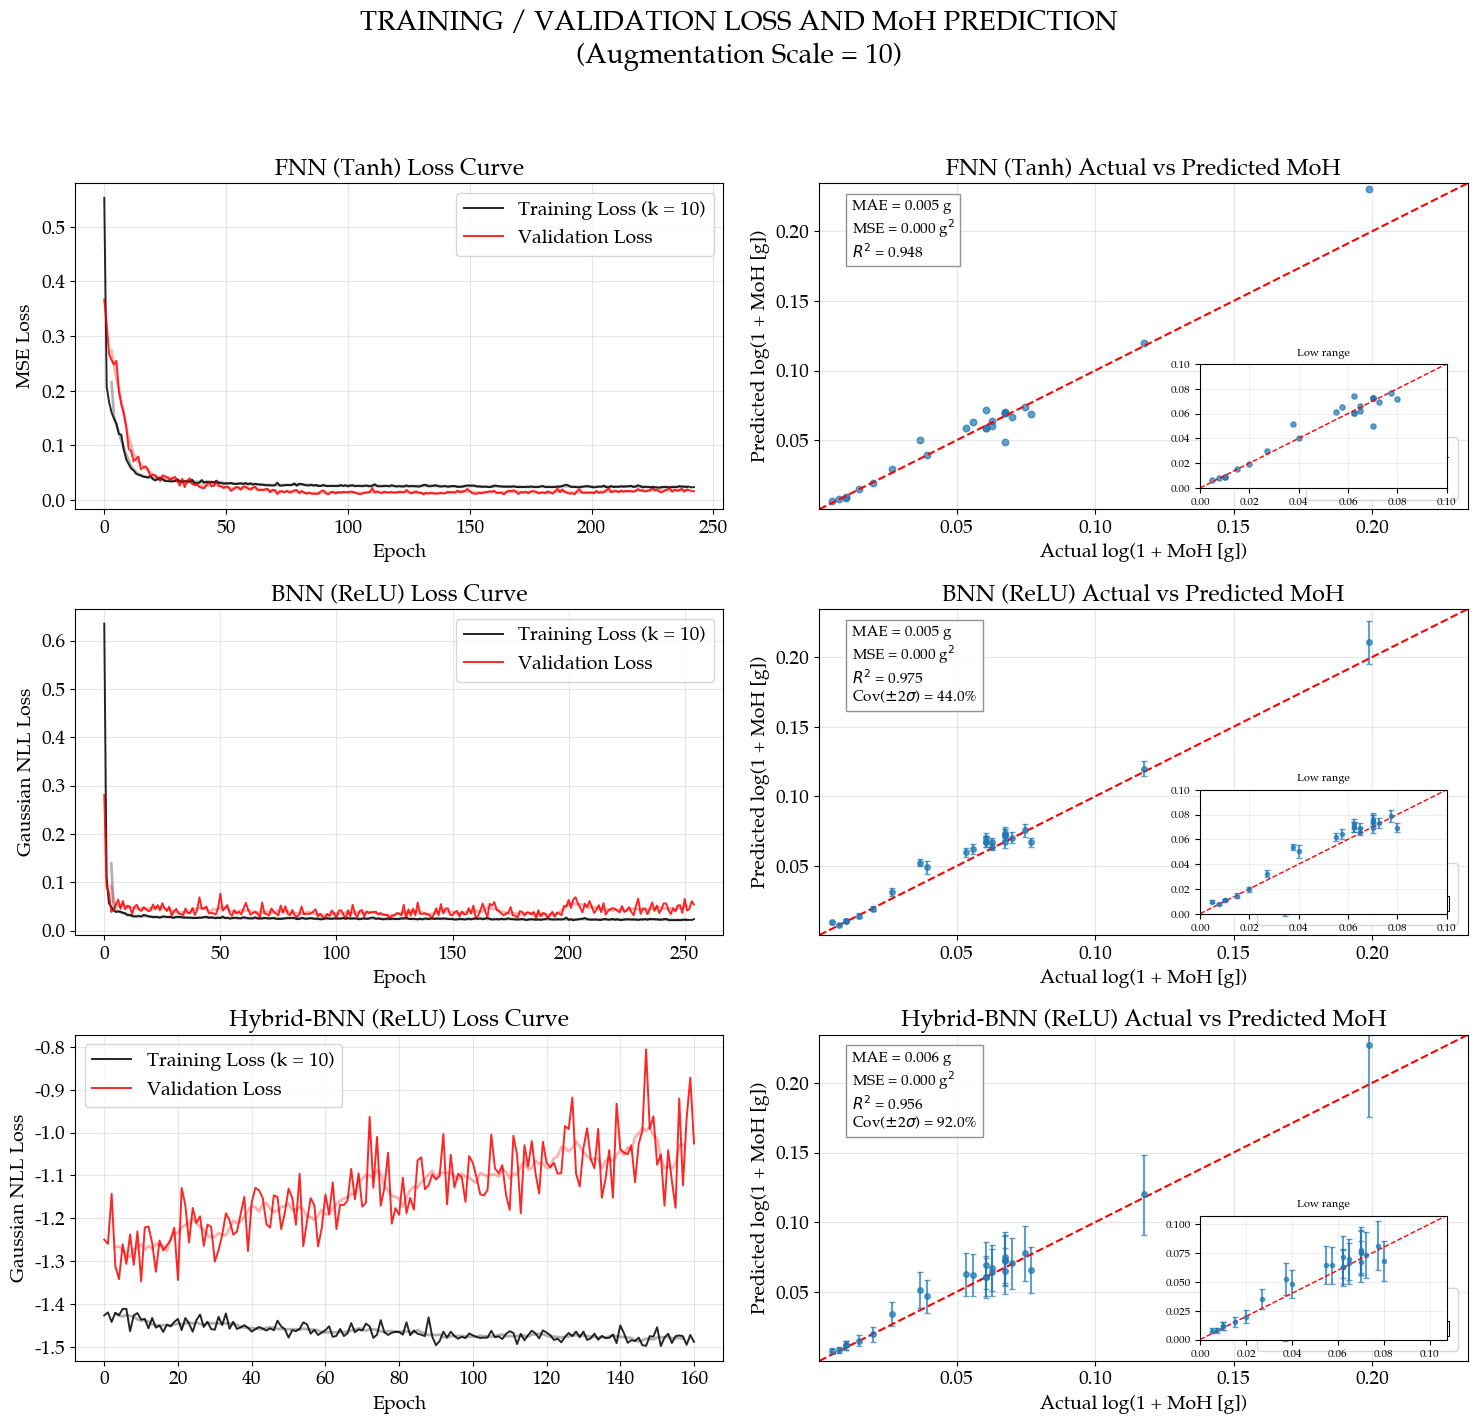


Saved figure: Model_Comparison_Plots_k10_final.png


In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


# Palatia typography (optional user-supplied font file)
font_path = "/content/Palatia.ttf"

if os.path.isfile(font_path):
    try:
        candidate_prop = fm.FontProperties(fname=font_path)
        candidate_name = candidate_prop.get_name()
        if "palatia" not in candidate_name.lower():
            raise ValueError(
                f"The supplied font identifies as '{candidate_name}', not Palatia."
            )
        fm.fontManager.addfont(font_path)
        prop = fm.FontProperties(fname=font_path)
        plt.rcParams["font.family"] = [prop.get_name()]
        print(f"Palatia font loaded: {candidate_name}")
    except Exception as exc:
        prop = fm.FontProperties(family="serif")
        plt.rcParams["font.family"] = ["serif"]
        print(f"Palatia font could not be loaded ({exc}); using Matplotlib serif fallback.")
else:
    prop = fm.FontProperties(family="serif")
    plt.rcParams["font.family"] = ["serif"]
    print("Palatia.ttf not found at /content/Palatia.ttf; using Matplotlib serif fallback.")

plt.rcParams["font.size"] = 14
plt.rcParams["font.weight"] = "normal"
plt.rcParams["text.usetex"] = False
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"


# Inputs expected from earlier blocks
models = ["FNN", "BNN", "Hybrid-BNN"]

train_losses_dict = {
    "FNN": fnn_train_losses,
    "BNN": bnn_train_losses,
    "Hybrid-BNN": hbnn_train_losses,
}

val_losses_dict = {
    "FNN": fnn_val_losses,
    "BNN": bnn_val_losses,
    "Hybrid-BNN": hbnn_val_losses,
}

results_dict = {
    "FNN": fnn_results,
    "BNN": bnn_results,
    "Hybrid-BNN": hbnn_results,
}

loss_type_label = {
    "FNN": "MSE Loss",
    "BNN": "Gaussian NLL Loss",
    "Hybrid-BNN": "Gaussian NLL Loss",
}

Z_SIGMA = 2.0

# Helpers configuration
def moving_average(arr, window=7):
    arr = np.asarray(arr, dtype=float)
    if len(arr) < window:
        return np.arange(len(arr)), arr
    kernel = np.ones(window) / window
    smoothed = np.convolve(arr, kernel, mode="valid")
    x_start = window // 2
    x_idx = np.arange(x_start, x_start + len(smoothed))
    return x_idx, smoothed


def safe_log1p(arr):
    arr = np.asarray(arr, dtype=float)
    return np.log1p(np.clip(arr, a_min=0.0, a_max=None))


def resolve_activation(model_name):

    result_block = results_dict[model_name]

    if len(result_block) == 0:
        raise ValueError(f"No results found for model: {model_name}")

    sample_key = next(iter(result_block))
    sample_result = result_block[sample_key]

    if "val_mae_g" in sample_result:
        return min(result_block, key=lambda a: result_block[a]["val_mae_g"])

    if "r2" in sample_result and "mae" in sample_result:
        return max(
            result_block,
            key=lambda a: (
                result_block[a].get("r2", -np.inf),
                -result_block[a].get("mae", np.inf)
            )
        )

    if "r2" in sample_result:
        return max(result_block, key=lambda a: result_block[a].get("r2", -np.inf))

    return next(iter(result_block))


def get_prediction_interval(result, z=Z_SIGMA):
    if "y_std" not in result:
        return None, None, "Predicted"

    y_pred = np.asarray(result["y_pred"], dtype=float).reshape(-1)
    y_std = np.asarray(result["y_std"], dtype=float).reshape(-1)

    lower = np.clip(y_pred - z * y_std, a_min=0.0, a_max=None)
    upper = np.clip(y_pred + z * y_std, a_min=0.0, a_max=None)

    return lower, upper, f"Prediction ±{int(z)}σ"


def build_annotation(model_name, result):
    mae = float(result["mae"])
    mse = float(result["mse"])
    r2 = float(result["r2"])

    lines = [
        f"MAE = {mae:.3f} g",
        f"MSE = {mse:.3f} g$^2$",
        f"$R^2$ = {r2:.3f}",
    ]

    if model_name in {"BNN", "Hybrid-BNN"} and "coverage_95(%)" in result:
        lines.append(f"Cov($\\pm${int(Z_SIGMA)}$\\sigma$) = {float(result['coverage_95(%)']):.1f}%")

    return "\n".join(lines)


# Activation selection
activations = {
    "FNN": resolve_activation("FNN"),
    "BNN": resolve_activation("BNN"),
    "Hybrid-BNN": resolve_activation("Hybrid-BNN"),
}

print("\nSelected activations for plotting:")
for model in models:
    print(f"  {model}: {activations[model]}")

# Shared graphical plot settings
LOW_REGION_MAX = 0.10
SMOOTH_WINDOW = 7

all_x_plot = []
all_y_plot = []
for model in models:
    act = activations[model]
    y_true_global = np.asarray(results_dict[model][act]["y_true"], dtype=float).reshape(-1)
    y_pred_global = np.asarray(results_dict[model][act]["y_pred"], dtype=float).reshape(-1)
    all_x_plot.append(safe_log1p(y_true_global))
    all_y_plot.append(safe_log1p(y_pred_global))

global_min = min(arr.min() for arr in all_x_plot + all_y_plot)
global_max = max(arr.max() for arr in all_x_plot + all_y_plot)

pad = 0.02 * max(global_max - global_min, 1e-6)
axis_min = max(0.0, global_min - pad)
axis_max = global_max + pad


# Figure Plotting
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(15, 15))
fig.suptitle(
    f"TRAINING / VALIDATION LOSS AND MoH PREDICTION\n(Augmentation Scale = {AUG_SCALE})",
    fontsize=20,
)


# Plot loop function
for idx, model in enumerate(models):
    act = activations[model]
    result = results_dict[model][act]


    # LEFT: LOSS CURVES
    ax1 = axes[idx, 0]

    train_loss = np.asarray(train_losses_dict[model][act], dtype=float)
    val_loss = np.asarray(val_losses_dict[model][act], dtype=float)
    epochs = np.arange(len(train_loss))

    ax1.plot(
        epochs,
        train_loss,
        color="black",
        linewidth=1.4,
        alpha=0.85,
        label=f"Training Loss (k = {AUG_SCALE})",
    )
    ax1.plot(
        epochs,
        val_loss,
        color="red",
        linewidth=1.4,
        alpha=0.85,
        label="Validation Loss",
    )

    x_smooth, train_smooth = moving_average(train_loss, SMOOTH_WINDOW)
    _, val_smooth = moving_average(val_loss, SMOOTH_WINDOW)

    ax1.plot(x_smooth, train_smooth, color="black", linewidth=2.0, alpha=0.30)
    ax1.plot(x_smooth, val_smooth, color="red", linewidth=2.0, alpha=0.30)

    ax1.set_title(f"{model} ({act}) Loss Curve")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel(loss_type_label[model])
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # RIGHT: ACTUAL VS PREDICTED
    ax2 = axes[idx, 1]

    y_true = np.asarray(result["y_true"], dtype=float).reshape(-1)
    y_pred = np.asarray(result["y_pred"], dtype=float).reshape(-1)

    x_plot = safe_log1p(y_true)
    y_plot = safe_log1p(y_pred)

    lower, upper, pred_label = get_prediction_interval(result, z=Z_SIGMA)

    if lower is not None and upper is not None:
        lower_log = safe_log1p(lower)
        upper_log = safe_log1p(upper)
        lower_err = np.clip(y_plot - lower_log, a_min=0.0, a_max=None)
        upper_err = np.clip(upper_log - y_plot, a_min=0.0, a_max=None)
        yerr_asym = np.vstack([lower_err, upper_err])

        ax2.errorbar(
            x_plot,
            y_plot,
            yerr=yerr_asym,
            fmt="o",
            markersize=4,
            alpha=0.7,
            capsize=2,
            label=pred_label,
        )
    else:
        ax2.scatter(x_plot, y_plot, s=22, alpha=0.7, label=pred_label)

    ax2.plot(
        [axis_min, axis_max],
        [axis_min, axis_max],
        "r--",
        linewidth=1.5,
        label="Ideal",
    )

    annotation = build_annotation(model, result)
    ax2.text(
        0.05,
        0.95,
        annotation,
        transform=ax2.transAxes,
        fontsize=11,
        verticalalignment="top",
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="gray"),
    )

    ax2.set_title(f"{model} ({act}) Actual vs Predicted MoH")
    ax2.set_xlabel("Actual log(1 + MoH [g])")
    ax2.set_ylabel("Predicted log(1 + MoH [g])")
    ax2.set_xlim(axis_min, axis_max)
    ax2.set_ylim(axis_min, axis_max)
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    # INSET: LOW RANGE IN ORIGINAL UNITS
    low_mask = y_true <= LOW_REGION_MAX

    if np.sum(low_mask) >= 2:
        axins = inset_axes(ax2, width="38%", height="38%", loc="lower right", borderpad=1.1)

        if lower is not None and upper is not None:
            low_true = y_true[low_mask]
            low_pred = y_pred[low_mask]
            low_lower = lower[low_mask]
            low_upper = upper[low_mask]
            low_yerr = np.vstack([
                np.clip(low_pred - low_lower, a_min=0.0, a_max=None),
                np.clip(low_upper - low_pred, a_min=0.0, a_max=None),
            ])

            axins.errorbar(
                low_true,
                low_pred,
                yerr=low_yerr,
                fmt="o",
                markersize=3,
                alpha=0.7,
                capsize=2,
            )
        else:
            axins.scatter(y_true[low_mask], y_pred[low_mask], s=14, alpha=0.7)

        low_max = max(
            LOW_REGION_MAX,
            y_true[low_mask].max() * 1.05,
            y_pred[low_mask].max() * 1.05,
        )

        if lower is not None and upper is not None:
            low_max = max(low_max, upper[low_mask].max() * 1.05)

        axins.plot([0.0, low_max], [0.0, low_max], "r--", linewidth=1.0)
        axins.set_xlim(0.0, low_max)
        axins.set_ylim(0.0, low_max)
        axins.set_title("Low range", fontsize=8)
        axins.tick_params(axis="both", labelsize=8)
        axins.grid(True, alpha=0.2)


# Final layout and save configuration
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
output_path = f"Model_Comparison_Plots_k{AUG_SCALE}_final.png"
plt.savefig(output_path, dpi=600, bbox_inches="tight")
plt.show()

print(f"\nSaved figure: {output_path}")